# 04 — Analisis Bivariat dan Multivariat
**Proyek EDA: Analisis Kebiasaan Penggunaan Ponsel Sebelum Tidur & Sleep Debt**
Exploratory Data Analysis (KMTI21133) · Milestone 3

**Pertanyaan payung:** Bagaimana kebiasaan memakai ponsel sebelum tidur berhubungan dengan kualitas tidur, sleep debt, dan kelelahan keesokan harinya?

**Pertanyaan turunan**
1. Bagaimana tren *sleep latency*, total tidur, dan kelelahan ketika durasi pakai ponsel sebelum tidur bertambah?
2. Apakah jenis aplikasi, kecerahan layar, dan filter cahaya biru membedakan *sleep latency*?
3. Variabel apa yang paling berhubungan dengan kelelahan, dan kelompok mana yang paling berisiko *sleep debt*?

## 0. Persiapan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

# Path RELATIF (aturan panduan). Jalankan dari folder notebooks/ (atau dari akar repositori).
NAMA = 'bedtime_screentime_sleep_debt_bersih.csv'
KANDIDAT = [f'../data/processed/{NAMA}', f'data/processed/{NAMA}', NAMA]
PATH = next((p for p in KANDIDAT if os.path.exists(p)), None)
if PATH is None:
    try:                                   # fallback khusus Colab: unggah manual
        from google.colab import files
        files.upload(); PATH = NAMA
    except ImportError:
        raise FileNotFoundError(f'Letakkan {NAMA} di data/processed/ lalu jalankan ulang.')

FIG = '../reports/figures' if PATH.startswith('../') else 'reports/figures'
os.makedirs(FIG, exist_ok=True)
def simpan(nama):
    plt.savefig(f'{FIG}/{nama}.png', dpi=150, bbox_inches='tight')

df = pd.read_csv(PATH)
print('Data      :', PATH)
print('Dimensi   :', df.shape)
print('Total NaN :', int(df.isna().sum().sum()))

Data      : ../data/processed/bedtime_screentime_sleep_debt_bersih.csv
Dimensi   : (8500, 18)
Total NaN : 0


In [2]:
from itertools import combinations

NUM = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct',
       'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
URUT_DEBT = ['Severe Sleep Debt', 'Moderate Debt', 'Mild Deficit', 'Optimal Recovery']

# `Unknown` diperlakukan sebagai kosong pada analisis ini
df_an = df.copy()
df_an[['occupation_type', 'chronotype']] = df_an[['occupation_type', 'chronotype']].replace('Unknown', np.nan)
print(df_an[['occupation_type', 'chronotype']].isna().sum())

occupation_type    170
chronotype         127
dtype: int64


## 1. Korelasi antar variabel numerik (Pearson dan Spearman)

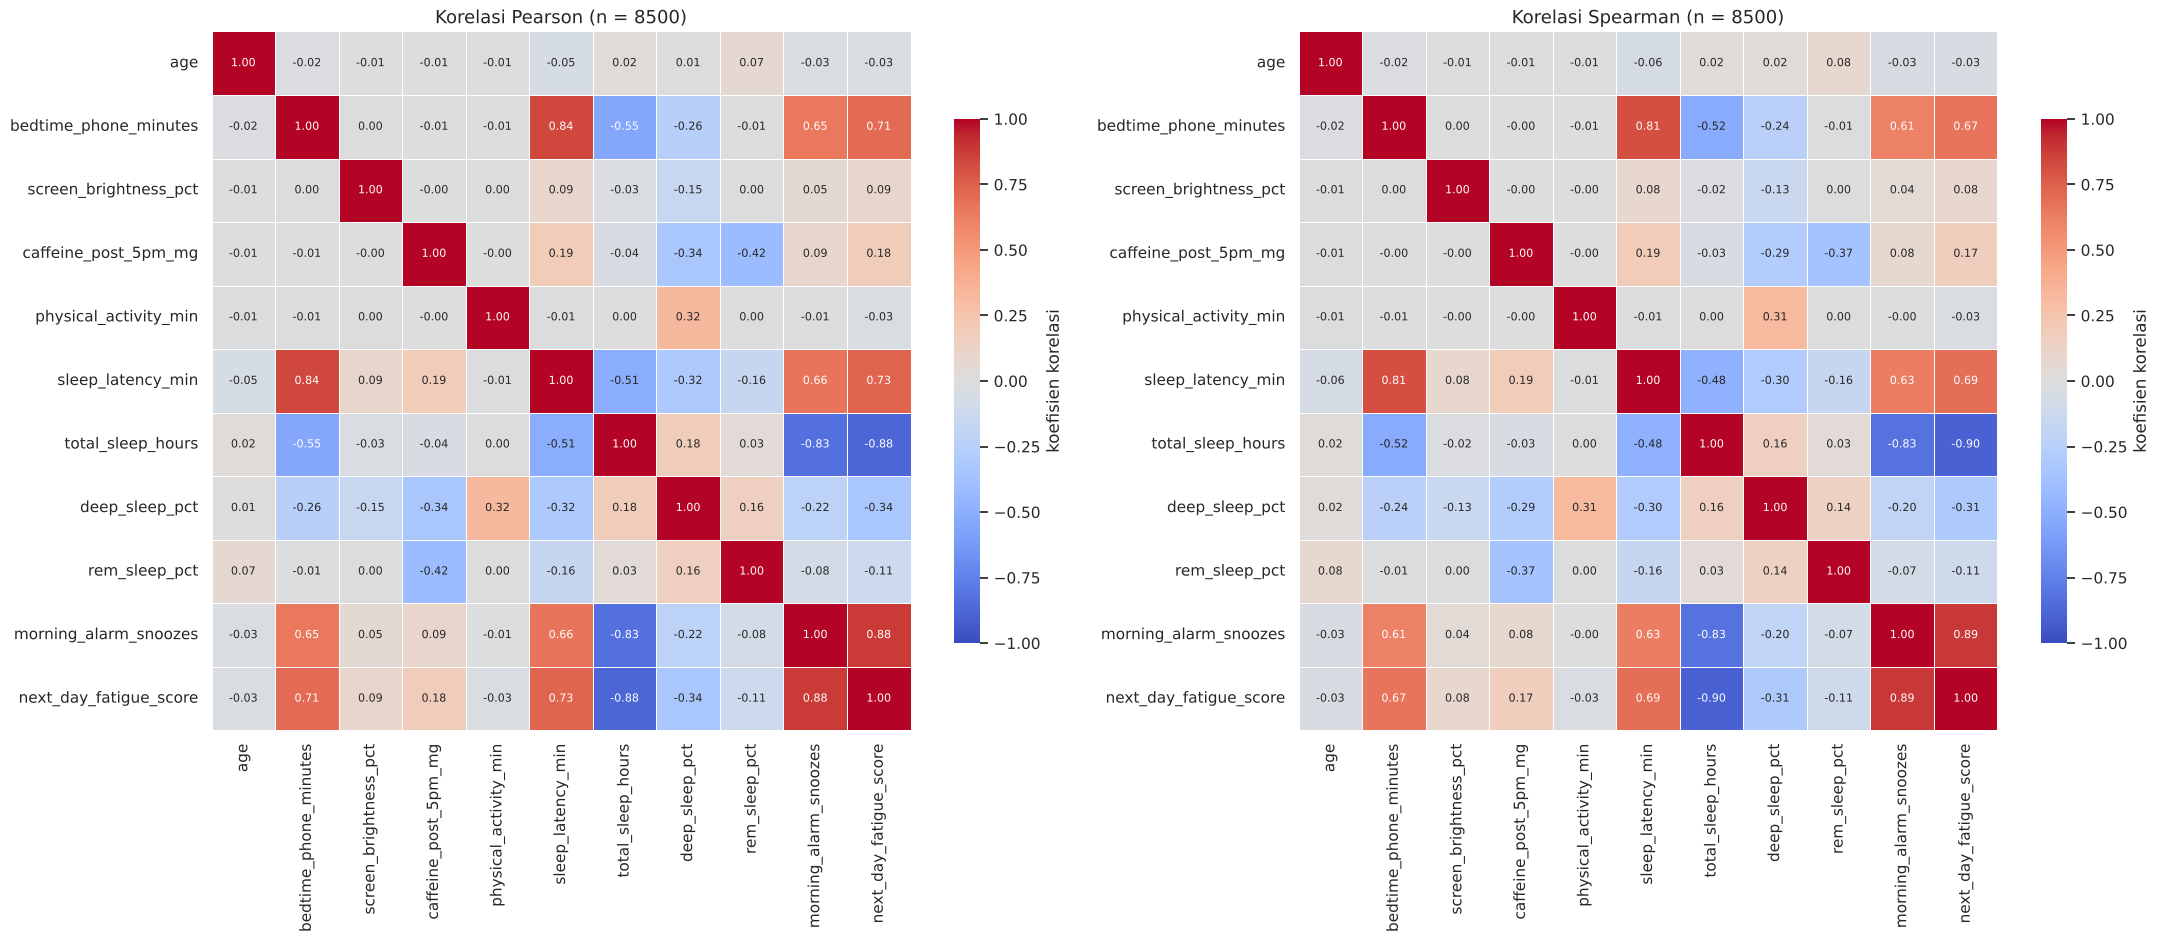

,x,y,n_dropna,pearson,spearman,|spearman|
0,total_sleep_hours,next_day_fatigue_score,8500,-0.88,-0.90,0.90
1,morning_alarm_snoozes,next_day_fatigue_score,8500,0.88,0.89,0.89
2,total_sleep_hours,morning_alarm_snoozes,8500,-0.83,-0.83,0.83
3,bedtime_phone_minutes,sleep_latency_min,8500,0.84,0.81,0.81
4,sleep_latency_min,next_day_fatigue_score,8500,0.73,0.69,0.69
5,bedtime_phone_minutes,next_day_fatigue_score,8500,0.71,0.67,0.67
6,sleep_latency_min,morning_alarm_snoozes,8500,0.66,0.63,0.63
7,bedtime_phone_minutes,morning_alarm_snoozes,8500,0.65,0.61,0.61
8,bedtime_phone_minutes,total_sleep_hours,8500,-0.55,-0.52,0.52
9,sleep_latency_min,total_sleep_hours,8500,-0.51,-0.48,0.48


In [3]:
n_lengkap = df_an[NUM].dropna().shape[0]
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, metode in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(df_an[NUM].corr(method=metode), vmin=-1, vmax=1, center=0, cmap='coolwarm',
                annot=True, fmt='.2f', annot_kws={'size': 8}, square=True, linewidths=.5, ax=ax,
                cbar_kws={'shrink': .75, 'label': 'koefisien korelasi'})
    ax.set_title(f'Korelasi {metode.capitalize()} (n = {n_lengkap})', fontsize=13)
plt.tight_layout(); simpan('multi_01_heatmap'); plt.show()

rows = []
for a, b in combinations(NUM, 2):
    p = df_an[[a, b]].dropna()
    rows.append((a, b, len(p), p.corr('pearson').iloc[0, 1], p.corr('spearman').iloc[0, 1]))
pairs = pd.DataFrame(rows, columns=['x', 'y', 'n_dropna', 'pearson', 'spearman'])
pairs['|spearman|'] = pairs['spearman'].abs()
pairs.sort_values('|spearman|', ascending=False).head(12).round(2).reset_index(drop=True)

Variabel yang berkaitan dengan durasi ponsel membentuk satu gugus: `sleep_latency_min` (ρ ≈ 0,81), `next_day_fatigue_score` (ρ ≈ 0,67), `morning_alarm_snoozes` (ρ ≈ 0,61), dan `total_sleep_hours` (ρ ≈ −0,52). Kelelahan sendiri paling berkaitan dengan `total_sleep_hours` (ρ ≈ −0,90) dan `morning_alarm_snoozes` (ρ ≈ 0,89). Variabel usia, kecerahan, aktivitas fisik, dan kafein hampir tidak berkorelasi dengan durasi ponsel.

Pasangan yang dipilih untuk scatter plot:
- **A:** `bedtime_phone_minutes` ↔ `sleep_latency_min` (pertanyaan 1 dan 2)
- **B:** `total_sleep_hours` ↔ `next_day_fatigue_score` (pertanyaan 3)

## 2. Pemilihan ukuran korelasi

In [4]:
def sifat(k):
    s = df_an[k].dropna()
    return pd.Series({'skew': s.skew(), '%_nol': 100 * (s == 0).mean(),
                      '%_di_min': 100 * (s == s.min()).mean(), '%_di_max': 100 * (s == s.max()).mean()})

pd.DataFrame({k: sifat(k) for k in ['bedtime_phone_minutes', 'sleep_latency_min', 'total_sleep_hours', 'next_day_fatigue_score']}).T.round(2)

,skew,%_nol,%_di_min,%_di_max
bedtime_phone_minutes,1.03,0.0,0.01,1.02
sleep_latency_min,1.00,0.0,0.05,0.01
total_sleep_hours,-0.16,0.0,2.85,0.20
next_day_fatigue_score,0.75,0.0,24.82,3.69


- **Pasangan A:** durasi ponsel (skew 1,03; terpotong di 180 menit) dan *sleep latency* (skew 1,00) sama-sama miring kanan, sehingga **Spearman** dipakai sebagai ukuran utama dan Pearson sebagai pembanding.
- **Pasangan B:** skor kelelahan menumpuk di 1,0 (24,8%) dan 10,0 (3,7%) dan hubungannya dengan total tidur melengkung, sehingga **Spearman** dipakai sebagai ukuran utama.

## 3. Pertanyaan 1: tren menurut durasi ponsel sebelum tidur

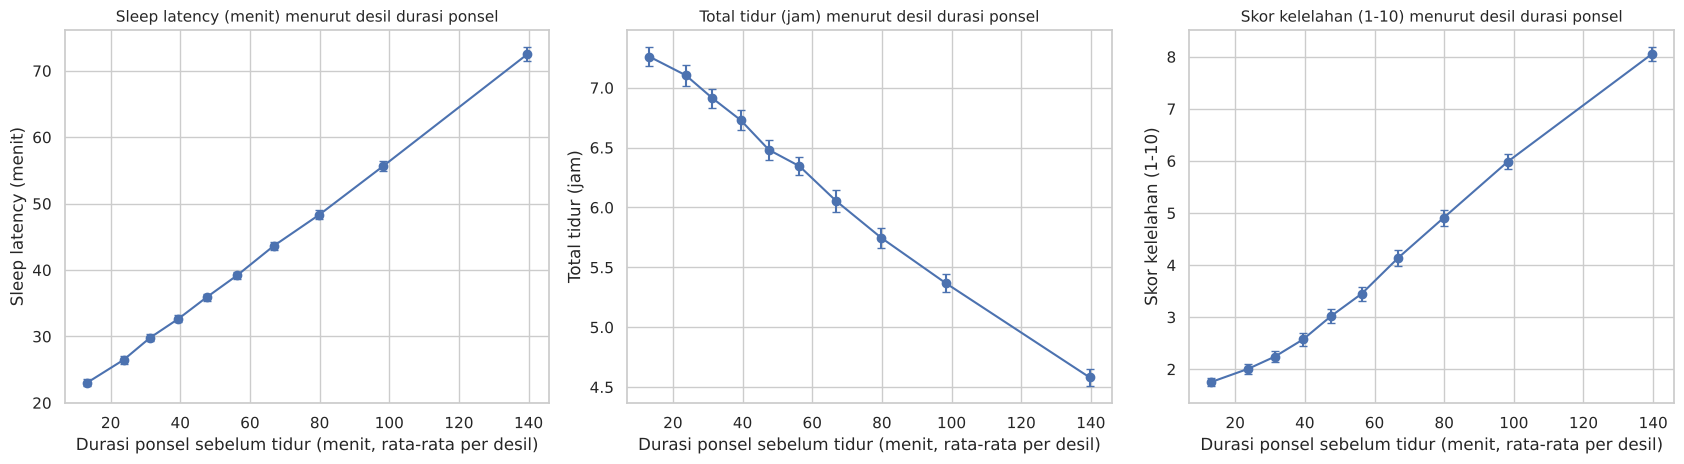

,n,ponsel_menit,sleep_latency_min,total_sleep_hours,next_day_fatigue_score
bedtime_phone_minutes,,,,,
"(0.999, 19.0]",883,13.2,23.01,7.26,1.76
"(19.0, 27.0]",824,23.7,26.47,7.10,2.01
"(27.0, 35.0]",866,31.4,29.82,6.91,2.24
"(35.0, 43.0]",850,39.5,32.66,6.73,2.57
"(43.0, 51.0]",837,47.6,35.89,6.48,3.02
"(51.0, 61.0]",908,56.3,39.21,6.34,3.45
"(61.0, 72.0]",804,66.9,43.65,6.05,4.14
"(72.0, 87.0]",854,79.9,48.31,5.75,4.91
"(87.0, 111.0]",846,98.3,55.66,5.37,5.99


In [5]:
OUT = [('sleep_latency_min', 'Sleep latency (menit)'),
       ('total_sleep_hours', 'Total tidur (jam)'),
       ('next_day_fatigue_score', 'Skor kelelahan (1-10)')]
desil = pd.qcut(df_an['bedtime_phone_minutes'], 10)
x_mean = df_an.groupby(desil, observed=True)['bedtime_phone_minutes'].mean()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (k, lab) in zip(axes, OUT):
    g = df_an.groupby(desil, observed=True)[k].agg(['mean', 'sem'])
    ax.errorbar(x_mean, g['mean'], yerr=1.96 * g['sem'], marker='o', capsize=3, color='#4C72B0')
    ax.set_xlabel('Durasi ponsel sebelum tidur (menit, rata-rata per desil)'); ax.set_ylabel(lab)
    ax.set_title(f'{lab} menurut desil durasi ponsel', fontsize=11)
plt.tight_layout(); simpan('multi_02_tren_desil'); plt.show()

tren = df_an.groupby(desil, observed=True)[[c_[0] for c_ in OUT]].mean().round(2)
tren.insert(0, 'ponsel_menit', x_mean.round(1)); tren.insert(0, 'n', desil.value_counts().sort_index().values)
tren

Ketiga ukuran bergerak searah dan makin curam di durasi ponsel tertinggi. Dari desil terendah (rata-rata 13 menit) ke desil tertinggi (rata-rata 140 menit), rata-rata *sleep latency* naik dari 23,0 ke 72,5 menit, total tidur turun dari 7,26 ke 4,58 jam, dan skor kelelahan naik dari 1,76 ke 8,05. Kenaikan *sleep latency* per desil kecil di awal (± 3 menit) dan membesar di ujung (± 17 menit antara dua desil teratas); pola serupa terlihat pada tidur dan kelelahan. Ini menggambarkan kecenderungan antar kelompok, bukan hubungan sebab-akibat.

## 4. Scatter plot pasangan terpilih

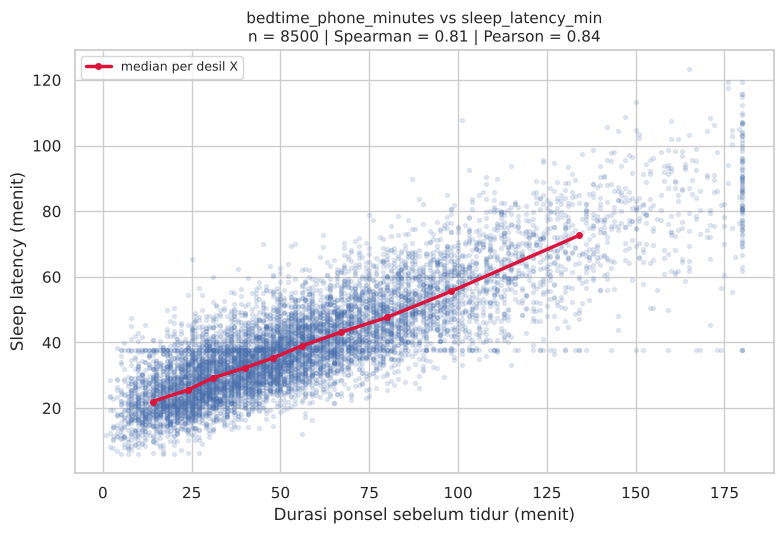

n setelah dropna = 8500 | Pearson = 0.842 | Spearman = 0.815


In [6]:
def scatter_tren(x, y, data, ax, judul=None):
    p = data[[x, y]].dropna()
    pr, sp = p.corr('pearson').iloc[0, 1], p.corr('spearman').iloc[0, 1]
    ax.scatter(p[x], p[y], s=8, alpha=.15, color='#4C72B0', rasterized=True)
    g = p.groupby(pd.qcut(p[x], 10, duplicates='drop'), observed=True).agg(xm=(x, 'median'), ym=(y, 'median'))
    ax.plot(g.xm, g.ym, color='crimson', lw=2.5, marker='o', ms=4, label='median per desil X')
    ax.set_xlabel(x); ax.set_ylabel(y); ax.legend(loc='best', fontsize=9)
    ax.set_title(judul or f'{x} vs {y}\nn = {len(p)} | Spearman = {sp:.2f} | Pearson = {pr:.2f}', fontsize=11)
    return len(p), pr, sp

fig, ax = plt.subplots(figsize=(8, 5.5))
nA, prA, spA = scatter_tren('bedtime_phone_minutes', 'sleep_latency_min', df_an, ax)
ax.set_xlabel('Durasi ponsel sebelum tidur (menit)'); ax.set_ylabel('Sleep latency (menit)')
plt.tight_layout(); simpan('multi_03_scatter_A'); plt.show()
print(f'n setelah dropna = {nA} | Pearson = {prA:.3f} | Spearman = {spA:.3f}')

**Scatter A: durasi ponsel ↔ *sleep latency*.** Hubungan positif kuat (Spearman ≈ 0,81; Pearson ≈ 0,84; n = 8.500 setelah `dropna()`). Orang dengan durasi ponsel lebih lama cenderung disertai waktu terlelap yang lebih lama. Pearson (0,84) dan Spearman (0,81) berdekatan; sebaran titik naik secara monoton dan melebar pada durasi ponsel yang tinggi. Titik yang menumpuk pada 180 menit mencerminkan batas pengukuran.

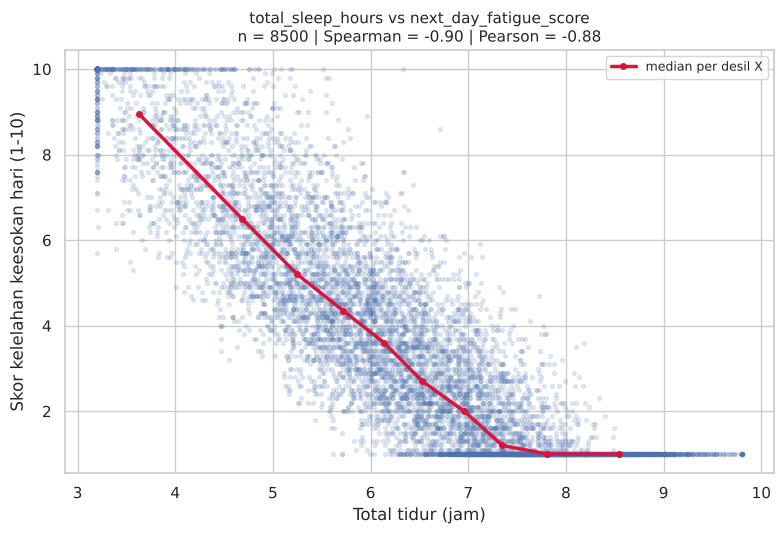

n setelah dropna = 8500 | Pearson = -0.879 | Spearman = -0.899


,count,mean,median
total_sleep_hours,,,
"(3, 4]",648,8.98,9.45
"(4, 5]",1084,6.85,6.70
"(5, 6]",1820,4.86,4.70
"(6, 7]",2101,2.98,2.90
"(7, 8]",1879,1.55,1.00
"(8, 10]",968,1.04,1.00


In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
nB, prB, spB = scatter_tren('total_sleep_hours', 'next_day_fatigue_score', df_an, ax)
ax.set_xlabel('Total tidur (jam)'); ax.set_ylabel('Skor kelelahan keesokan hari (1-10)')
plt.tight_layout(); simpan('multi_04_scatter_B'); plt.show()
print(f'n setelah dropna = {nB} | Pearson = {prB:.3f} | Spearman = {spB:.3f}')

kelas = pd.cut(df_an['total_sleep_hours'], [3, 4, 5, 6, 7, 8, 10])
display(df_an.groupby(kelas, observed=True)['next_day_fatigue_score'].agg(['count', 'mean', 'median']).round(2))

**Scatter B: total tidur ↔ kelelahan.** Hubungan negatif sangat kuat (Spearman ≈ −0,90; Pearson ≈ −0,88; n = 8.500 setelah `dropna()`) dan **melengkung**: skor kelelahan rata-rata sekitar 9,0 pada tidur 3–4 jam, turun menjadi 6,9; 4,9; dan 3,0 pada kelas tidur berikutnya, lalu mendatar di kisaran 1,0–1,6 setelah tidur melewati ± 7 jam. Pendataran ini terkait efek lantai skor (24,8% responden bernilai tepat 1,0). Tidur yang lebih pendek cenderung disertai kelelahan yang lebih tinggi.

## 5. Faceting scatter A menurut aplikasi sebelum tidur

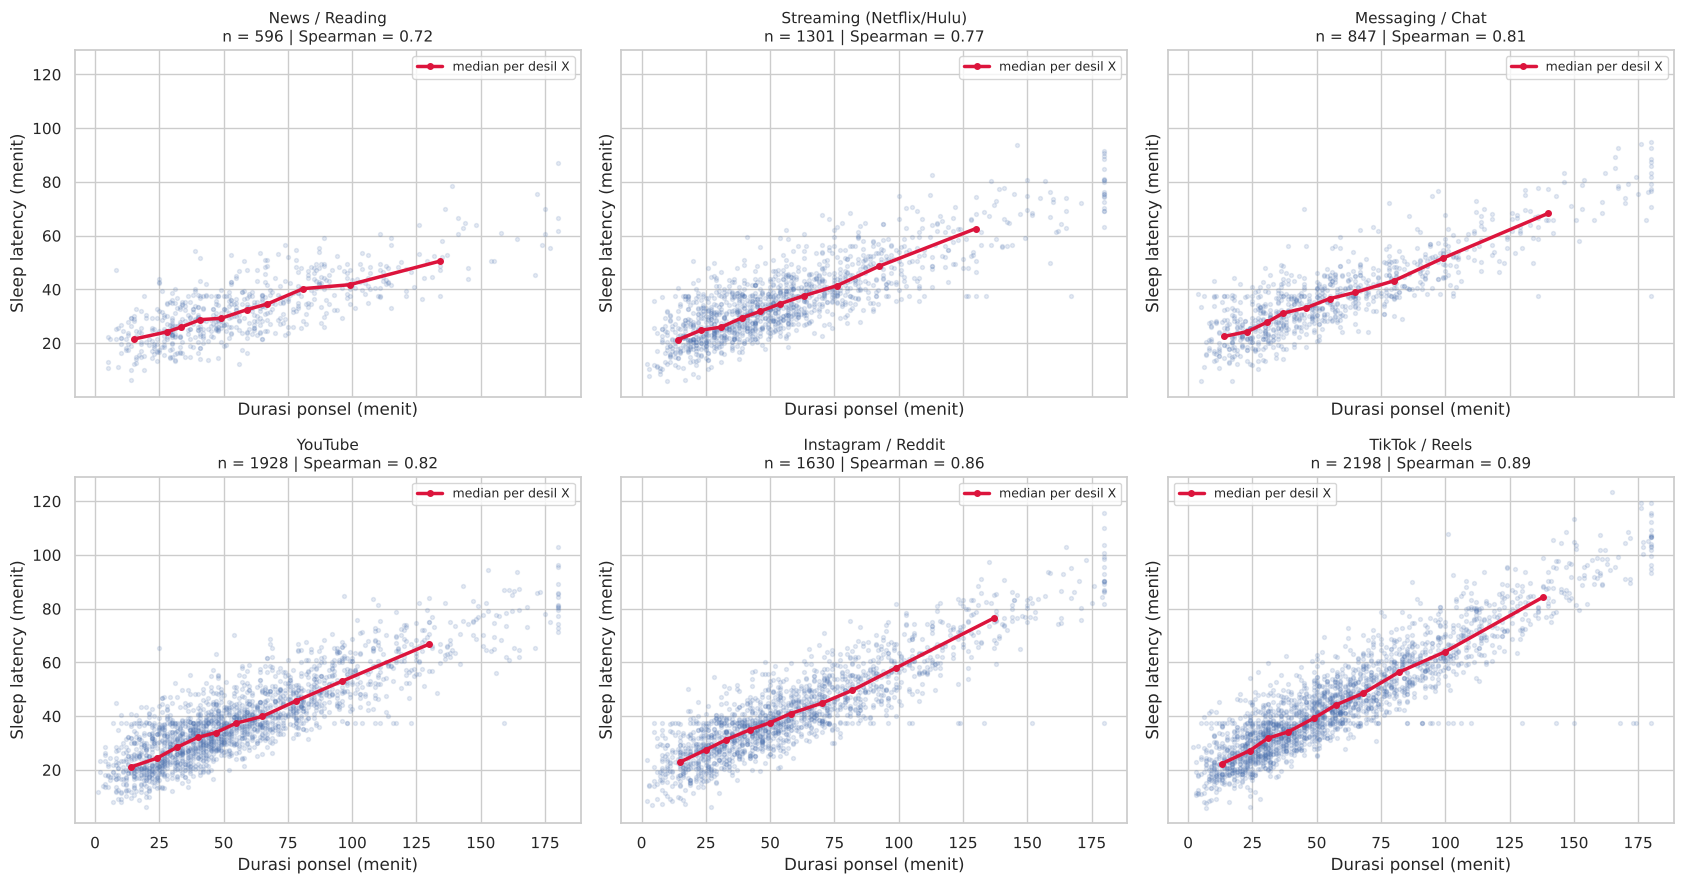

,n,spearman,pearson,mean_ponsel_menit,mean_latency_menit,selisih_latency_per_+30mnt_ponsel
aplikasi,,,,,,
News / Reading,596,0.72,0.76,60.09,33.23,7.61
Streaming (Netflix/Hulu),1301,0.77,0.82,57.11,36.43,9.80
Messaging / Chat,847,0.81,0.86,59.46,38.34,10.31
YouTube,1928,0.82,0.85,58.29,39.06,11.03
Instagram / Reddit,1630,0.86,0.88,60.86,42.43,12.27
TikTok / Reels,2198,0.89,0.90,59.85,45.80,14.35


In [8]:
urut_app = df_an.groupby('primary_bedtime_app')['sleep_latency_min'].mean().sort_values().index
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
baris = []
for ax, k in zip(axes.ravel(), urut_app):
    sub = df_an[df_an['primary_bedtime_app'] == k]
    pp = sub[['bedtime_phone_minutes', 'sleep_latency_min']].dropna()
    n_k, pr_k, sp_k = scatter_tren('bedtime_phone_minutes', 'sleep_latency_min', sub, ax,
                                   judul=f'{k}\nn = {len(pp)} | Spearman = {pp.corr("spearman").iloc[0, 1]:.2f}')
    ax.set_xlabel('Durasi ponsel (menit)'); ax.set_ylabel('Sleep latency (menit)')
    baris.append({'aplikasi': k, 'n': n_k, 'spearman': sp_k, 'pearson': pr_k,
                  'mean_ponsel_menit': sub['bedtime_phone_minutes'].mean(),
                  'mean_latency_menit': sub['sleep_latency_min'].mean(),
                  'selisih_latency_per_+30mnt_ponsel': np.polyfit(pp.iloc[:, 0], pp.iloc[:, 1], 1)[0] * 30})
plt.tight_layout(); simpan('multi_05_facet_aplikasi'); plt.show()
pd.DataFrame(baris).round(2).set_index('aplikasi')

Pola tidak berubah: hubungan tetap positif di keenam aplikasi (Spearman 0,72–0,89), dengan sumbu x dan y yang sama pada semua panel. Yang berbeda adalah kemiringannya. Setiap tambahan 30 menit ponsel disertai kenaikan *sleep latency* sekitar 14,4 menit pada pengguna TikTok/Reels dan 12,3 menit pada Instagram/Reddit, dibanding 7,6 menit pada pengguna News/Reading. Rata-rata durasi ponsel antar aplikasi hampir sama (57–61 menit), sehingga perbedaan *sleep latency* antar aplikasi tidak sekadar mencerminkan perbedaan lama pemakaian.

## 6. Pertanyaan 2: aplikasi, kecerahan layar, dan filter cahaya biru terhadap *sleep latency*

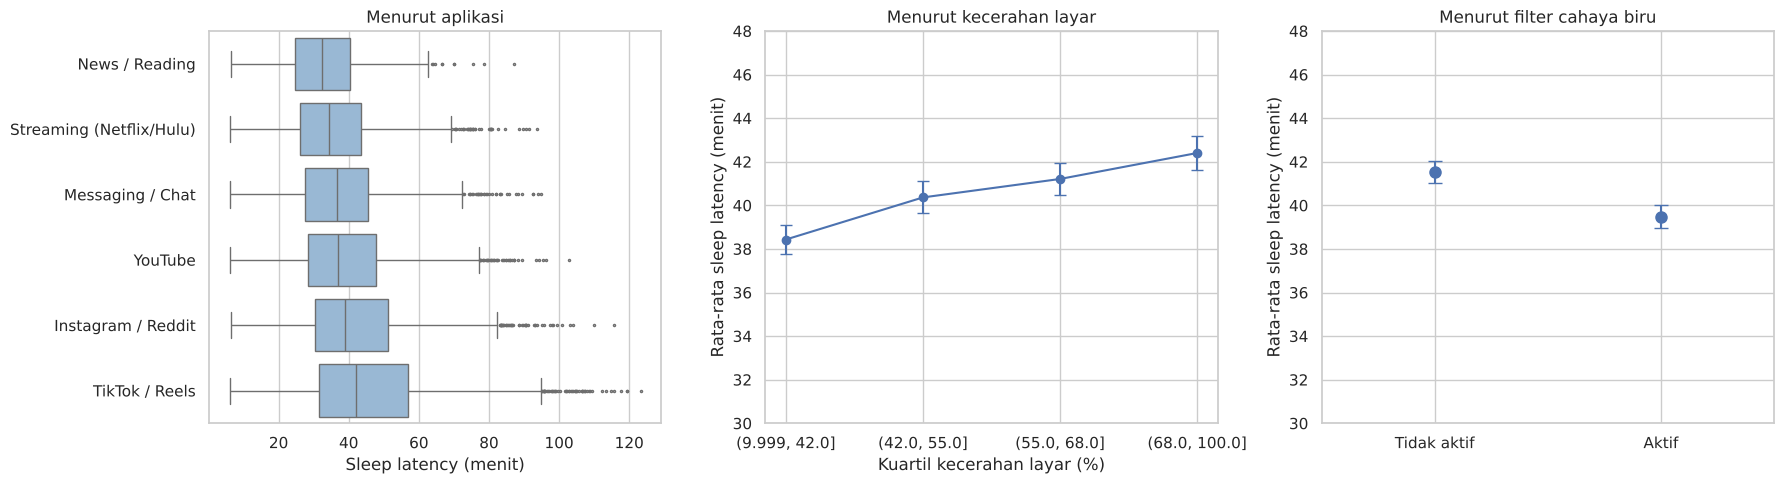

,Aplikasi,Kecerahan,Filter cahaya biru
uji,"Kruskal-Wallis H = 378, p = 1.4e-79","Spearman = 0.08, p = 7.0e-14",Mann-Whitney p = 1.4e-07
ukuran efek,eta^2 = 0.052,rata-rata kuartil 4 - kuartil 1 = 4.0 menit,selisih rata-rata (aktif - tidak) = -2.0 menit


,count,mean,median
primary_bedtime_app,,,
TikTok / Reels,2198,45.8,42.0
Instagram / Reddit,1630,42.4,39.0
YouTube,1928,39.1,37.0
Messaging / Chat,847,38.3,36.8
Streaming (Netflix/Hulu),1301,36.4,34.5
News / Reading,596,33.2,32.2


,selisih_dari_prediksi_(menit)
primary_bedtime_app,
TikTok / Reels,5.0
Instagram / Reddit,1.2
YouTube,-1.1
Messaging / Chat,-2.3
Streaming (Netflix/Hulu),-3.3
News / Reading,-7.7


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df_an, x='sleep_latency_min', y='primary_bedtime_app', order=urut_app, ax=axes[0], color='#8FB8DE', fliersize=1.5)
axes[0].set_xlabel('Sleep latency (menit)'); axes[0].set_ylabel(''); axes[0].set_title('Menurut aplikasi')

df_an['kecerahan_kuartil'] = pd.qcut(df_an['screen_brightness_pct'], 4)
g = df_an.groupby('kecerahan_kuartil', observed=True)['sleep_latency_min'].agg(['mean', 'sem'])
axes[1].errorbar(range(4), g['mean'], yerr=1.96 * g['sem'], marker='o', capsize=4, color='#4C72B0')
axes[1].set_xticks(range(4)); axes[1].set_xticklabels([str(i) for i in g.index])
axes[1].set_xlabel('Kuartil kecerahan layar (%)'); axes[1].set_ylabel('Rata-rata sleep latency (menit)'); axes[1].set_title('Menurut kecerahan layar')

g2 = df_an.groupby('blue_light_filter_active')['sleep_latency_min'].agg(['mean', 'sem'])
axes[2].errorbar([0, 1], g2['mean'], yerr=1.96 * g2['sem'], fmt='o', capsize=5, ms=8, color='#4C72B0')
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(['Tidak aktif', 'Aktif']); axes[2].set_xlim(-.5, 1.5)
axes[2].set_ylabel('Rata-rata sleep latency (menit)'); axes[2].set_title('Menurut filter cahaya biru')
for ax in axes[1:]: ax.set_ylim(30, 48)
plt.tight_layout(); simpan('multi_06_q2_latency'); plt.show()

# uji + ukuran efek
kw = stats.kruskal(*[s['sleep_latency_min'].values for _, s in df_an.groupby('primary_bedtime_app')])
def eta2(num, kat, data):
    p = data[[num, kat]].dropna()
    tot = ((p[num] - p[num].mean()) ** 2).sum()
    return sum(len(g) * (g.mean() - p[num].mean()) ** 2 for _, g in p.groupby(kat)[num]) / tot
a1 = df_an.loc[df_an.blue_light_filter_active == 1, 'sleep_latency_min']; a0 = df_an.loc[df_an.blue_light_filter_active == 0, 'sleep_latency_min']
mw = stats.mannwhitneyu(a1, a0)
rho_b = stats.spearmanr(df_an['screen_brightness_pct'], df_an['sleep_latency_min'])

ringkas_q2 = pd.DataFrame({
    'Aplikasi': [f'Kruskal-Wallis H = {kw.statistic:.0f}, p = {kw.pvalue:.1e}', f'eta^2 = {eta2("sleep_latency_min", "primary_bedtime_app", df_an):.3f}'],
    'Kecerahan': [f'Spearman = {rho_b.statistic:.2f}, p = {rho_b.pvalue:.1e}', f'rata-rata kuartil 4 - kuartil 1 = {g["mean"].iloc[-1] - g["mean"].iloc[0]:.1f} menit'],
    'Filter cahaya biru': [f'Mann-Whitney p = {mw.pvalue:.1e}', f'selisih rata-rata (aktif - tidak) = {a1.mean() - a0.mean():.1f} menit'],
}, index=['uji', 'ukuran efek'])
display(ringkas_q2)
display(df_an.groupby('primary_bedtime_app')['sleep_latency_min'].agg(['count', 'mean', 'median']).round(1).loc[urut_app[::-1]])

# perbedaan antar aplikasi setelah durasi ponsel diperhitungkan (residu regresi latency ~ ponsel)
b = np.polyfit(df_an['bedtime_phone_minutes'], df_an['sleep_latency_min'], 1)
df_an['latency_residu'] = df_an['sleep_latency_min'] - np.polyval(b, df_an['bedtime_phone_minutes'])
df_an.groupby('primary_bedtime_app')['latency_residu'].mean().round(1).sort_values(ascending=False).to_frame('selisih_dari_prediksi_(menit)')

- **Aplikasi** membedakan *sleep latency* paling jelas: rata-rata 45,8 menit pada TikTok/Reels dan 42,4 pada Instagram/Reddit, dibanding 33,2 menit pada News/Reading (selisih ≈ 12,6 menit; Kruskal-Wallis p < 0,001; η² ≈ 0,05). Urutan ini bertahan setelah durasi ponsel diperhitungkan (TikTok/Reels +5,0 menit dan News/Reading −7,7 menit dari prediksi berdasarkan durasi ponsel).
- **Kecerahan layar** berkaitan lemah dengan *sleep latency* (Spearman ≈ 0,08): rata-rata naik dari 38,4 menit pada kuartil kecerahan terendah menjadi 42,4 menit pada kuartil tertinggi, selisih ± 4 menit.
- **Filter cahaya biru** hanya berselisih ± 2 menit (39,5 menit saat aktif vs 41,5 menit saat tidak aktif), dengan median hampir sama (37,0 vs 37,7).

Pada n sebesar ini uji signifikansi hampir selalu bermakna, sehingga ukuran efeknya yang dipakai untuk menilai. Ketiganya berkaitan dengan *sleep latency*, tetapi jauh lebih lemah daripada durasi ponsel (Spearman ≈ 0,81).

## 7. Pertanyaan 3: variabel yang paling berhubungan dengan kelelahan

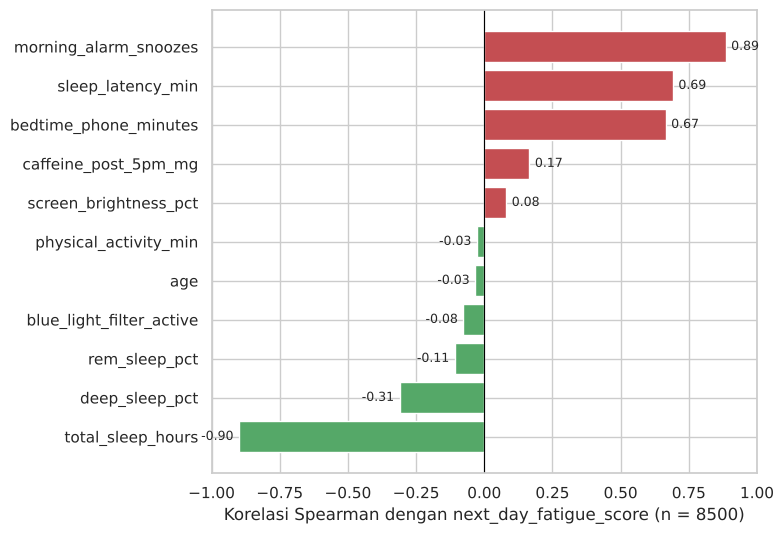

,eta^2 vs kelelahan
chronotype,0.165
occupation_type,0.056
primary_bedtime_app,0.011
gender,0.000


In [10]:
KOR = NUM[:-1] + ['blue_light_filter_active']
rho = pd.Series({k: df_an[[k, 'next_day_fatigue_score']].dropna().corr('spearman').iloc[0, 1] for k in KOR}).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(rho.index, rho.values, color=np.where(rho.values < 0, '#55A868', '#C44E52'))
ax.axvline(0, color='black', lw=.8); ax.set_xlim(-1, 1)
for i, v in enumerate(rho.values): ax.text(v + (.02 if v >= 0 else -.02), i, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.set_xlabel(f'Korelasi Spearman dengan next_day_fatigue_score (n = {len(df_an)})')
plt.tight_layout(); simpan('multi_07_korelasi_kelelahan'); plt.show()

eta_tbl = pd.DataFrame({'eta^2 vs kelelahan': {k: eta2('next_day_fatigue_score', k, df_an) for k in ['chronotype', 'occupation_type', 'primary_bedtime_app', 'gender']}}).round(3)
eta_tbl

Variabel numerik yang paling berkaitan dengan kelelahan adalah `total_sleep_hours` (ρ ≈ −0,90) dan `morning_alarm_snoozes` (ρ ≈ 0,89), disusul `sleep_latency_min` (ρ ≈ 0,69) dan durasi ponsel (ρ ≈ 0,67). Tidur dalam (ρ ≈ −0,31) dan kafein (ρ ≈ 0,17) berkaitan lebih lemah, sedangkan variabel lainnya |ρ| ≤ 0,11. Pada variabel kategorikal, kronotipe paling berkaitan (η² ≈ 0,17), diikuti pekerjaan (η² ≈ 0,06); aplikasi (η² ≈ 0,01) dan gender (η² ≈ 0) nyaris tidak berkaitan. Total tidur dan jumlah snooze adalah konsekuensi tidur yang kurang, bukan faktor yang berdiri sendiri.

## 8. Kelompok berisiko *sleep debt*: crosstab dinormalkan per baris dan Cramér's V

=== chronotype: Cramer V = 0.410 | chi2 = 2819 (dof 6) | n setelah dropna = 8373 | frekuensi harapan min = 161.7


sleep_debt_category,Severe Sleep Debt,Moderate Debt,Mild Deficit,Optimal Recovery,n_baris
chronotype,,,,,
Intermediate,5.8,50.2,32.0,12.0,3828
Morning Lark,2.6,24.4,30.5,42.5,2135
Night Owl,14.8,81.0,4.0,0.2,2410


=== occupation_type: Cramer V = 0.140 | chi2 = 493 (dof 12) | n setelah dropna = 8330 | frekuensi harapan min = 67.2


sleep_debt_category,Severe Sleep Debt,Moderate Debt,Mild Deficit,Optimal Recovery,n_baris
occupation_type,,,,,
Corporate 9-to-5,6.4,49.6,25.4,18.6,2781
Freelance / Creative,6.9,50.6,25.9,16.5,879
Healthcare / Shift Worker,18.1,71.6,8.7,1.6,982
Remote Tech,5.8,50.8,24.8,18.5,2104
Student,6.1,49.2,26.3,18.4,1584


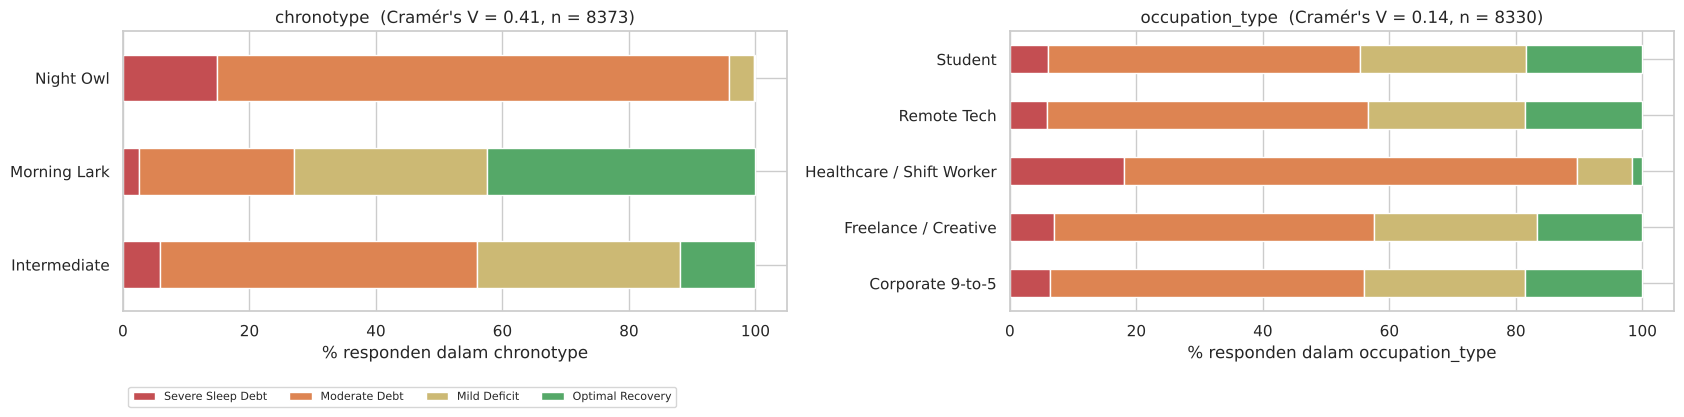

,V,n_dropna,min_expected
chronotype,0.410,8373.0,161.661292
occupation_type,0.140,8330.0,67.217647
primary_bedtime_app,0.048,8500.0,45.366118
gender,0.016,8500.0,18.877176


In [11]:
def cramers_v(a, b, data):
    d = data[[a, b]].dropna()
    ct = pd.crosstab(d[a], d[b])
    chi2, pval, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum()
    return {'V': np.sqrt(chi2 / (n * (min(ct.shape) - 1))), 'chi2': chi2, 'dof': dof, 'p': pval, 'n_dropna': n, 'min_expected': exp.min()}

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, k in zip(axes, ['chronotype', 'occupation_type']):
    ct_n = (pd.crosstab(df_an[k], df_an['sleep_debt_category'], normalize='index')[URUT_DEBT] * 100).round(1)
    ct_n['n_baris'] = pd.crosstab(df_an[k], df_an['sleep_debt_category']).sum(axis=1)
    hasil = cramers_v(k, 'sleep_debt_category', df_an)
    print(f'=== {k}: Cramer V = {hasil["V"]:.3f} | chi2 = {hasil["chi2"]:.0f} (dof {hasil["dof"]}) | n setelah dropna = {hasil["n_dropna"]} | frekuensi harapan min = {hasil["min_expected"]:.1f}')
    display(ct_n)
    ct_n[URUT_DEBT].plot(kind='barh', stacked=True, ax=ax, color=['#C44E52', '#DD8452', '#CCB974', '#55A868'], legend=False)
    ax.set_xlabel(f'% responden dalam {k}'); ax.set_ylabel('')
    ax.set_title(f"{k}  (Cramér's V = {hasil['V']:.2f}, n = {hasil['n_dropna']})")
axes[0].legend(bbox_to_anchor=(0, -.25), loc='upper left', ncol=4, fontsize=8)
plt.tight_layout(); simpan('multi_08_crosstab'); plt.show()

kat = ['chronotype', 'occupation_type', 'primary_bedtime_app', 'gender']
tbl = pd.DataFrame({k: cramers_v(k, 'sleep_debt_category', df_an) for k in kat}).T[['V', 'n_dropna', 'min_expected']]
tbl['V'] = tbl['V'].astype(float).round(3)
tbl.sort_values('V', ascending=False)

- **Kronotipe** adalah pembeda terkuat (Cramér's V ≈ 0,41; n = 8.373 setelah `dropna()`; semua frekuensi harapan ≥ 5 sehingga asumsi uji χ² terpenuhi). *Night Owl*: 81,0% *Moderate Debt* dan 14,8% *Severe*, hampir tidak ada yang *Optimal Recovery* (0,2%). *Morning Lark*: 42,5% *Optimal Recovery* dan hanya 2,6% *Severe*. *Intermediate* berada di antaranya.
- **Pekerjaan** (V ≈ 0,14; n = 8.330): *Healthcare / Shift Worker* paling berisiko (71,6% *Moderate* dan 18,1% *Severe*), sedangkan keempat kelompok pekerjaan lain relatif serupa (± 50% *Moderate* dan 6–7% *Severe*).
- **Aplikasi** (V ≈ 0,05) dan **gender** (V ≈ 0,02) nyaris tidak berkaitan dengan kategori *sleep debt*.

Kelompok yang paling berisiko adalah *Night Owl* dan pekerja *Healthcare / Shift*.

## 9. Kandidat variabel perancu

In [12]:
def kandidat(X, Y, num, kat):
    baris = []
    for k in num:
        p = df_an[[k, X, Y]].dropna()
        baris.append({'kandidat': k, 'ukuran': 'Spearman', 'dg_X': p.corr('spearman').loc[k, X], 'dg_Y': p.corr('spearman').loc[k, Y]})
    for k in kat:
        baris.append({'kandidat': k, 'ukuran': 'eta^2', 'dg_X': eta2(X, k, df_an), 'dg_Y': eta2(Y, k, df_an)})
    return pd.DataFrame(baris).set_index('kandidat').round(3)

def sesuaikan(X, Y, num, kat):
    d = df_an[[X, Y] + num + kat].dropna()
    Z = pd.concat([d[num], pd.get_dummies(d[kat], drop_first=True).astype(float)], axis=1)
    A = np.c_[np.ones(len(Z)), Z.values.astype(float)]
    sisa = lambda v: v.rank().values - A @ np.linalg.lstsq(A, v.rank().values, rcond=None)[0]
    return len(d), d[[X, Y]].corr('spearman').iloc[0, 1], np.corrcoef(sisa(d[X]), sisa(d[Y]))[0, 1]

NUM_K = ['age', 'caffeine_post_5pm_mg', 'physical_activity_min', 'screen_brightness_pct', 'blue_light_filter_active']
KAT_K = ['chronotype', 'occupation_type', 'primary_bedtime_app', 'gender']

print('--- A: durasi ponsel (X) -> sleep latency (Y)')
display(kandidat('bedtime_phone_minutes', 'sleep_latency_min', NUM_K, KAT_K))
n_, mentah, adj = sesuaikan('bedtime_phone_minutes', 'sleep_latency_min', NUM_K, KAT_K)
print(f'n = {n_} | Spearman mentah = {mentah:.2f} | setelah disesuaikan = {adj:.2f}')

print('\n--- B: total tidur (X) -> kelelahan (Y)')
display(kandidat('total_sleep_hours', 'next_day_fatigue_score', NUM_K + ['bedtime_phone_minutes'], KAT_K))
n_, mentah, adj = sesuaikan('total_sleep_hours', 'next_day_fatigue_score', NUM_K, KAT_K)
print(f'n = {n_} | Spearman mentah = {mentah:.2f} | disesuaikan (tanpa ponsel) = {adj:.2f}')
n_, mentah, adj = sesuaikan('total_sleep_hours', 'next_day_fatigue_score', NUM_K + ['bedtime_phone_minutes'], KAT_K)
print(f'n = {n_} | Spearman mentah = {mentah:.2f} | disesuaikan (dengan ponsel) = {adj:.2f}')
for k, s in df_an.dropna(subset=['chronotype']).groupby('chronotype'):
    print(f'  Spearman B dalam {k}: {s[["total_sleep_hours", "next_day_fatigue_score"]].corr("spearman").iloc[0, 1]:.2f} (n = {len(s)})')

--- A: durasi ponsel (X) -> sleep latency (Y)


,ukuran,dg_X,dg_Y
kandidat,,,
age,Spearman,-0.019,-0.059
caffeine_post_5pm_mg,Spearman,-0.003,0.194
physical_activity_min,Spearman,-0.005,-0.012
screen_brightness_pct,Spearman,0.002,0.081
blue_light_filter_active,Spearman,0.004,-0.057
chronotype,eta^2,0.000,0.000
occupation_type,eta^2,0.000,0.000
primary_bedtime_app,eta^2,0.001,0.052
gender,eta^2,0.000,0.000


n = 8205 | Spearman mentah = 0.81 | setelah disesuaikan = 0.86

--- B: total tidur (X) -> kelelahan (Y)


,ukuran,dg_X,dg_Y
kandidat,,,
age,Spearman,0.018,-0.033
caffeine_post_5pm_mg,Spearman,-0.032,0.166
physical_activity_min,Spearman,0.004,-0.027
screen_brightness_pct,Spearman,-0.023,0.081
blue_light_filter_active,Spearman,0.039,-0.077
bedtime_phone_minutes,Spearman,-0.525,0.665
chronotype,eta^2,0.374,0.165
occupation_type,eta^2,0.099,0.056
primary_bedtime_app,eta^2,0.003,0.011


n = 8205 | Spearman mentah = -0.90 | disesuaikan (tanpa ponsel) = -0.90
n = 8205 | Spearman mentah = -0.90 | disesuaikan (dengan ponsel) = -0.75
  Spearman B dalam Intermediate: -0.89 (n = 3828)
  Spearman B dalam Morning Lark: -0.85 (n = 2135)
  Spearman B dalam Night Owl: -0.89 (n = 2410)


**Pasangan A (durasi ponsel ↔ *sleep latency*).** Tidak ada kandidat yang berkaitan dengan *kedua* sisi. Usia, kafein, aktivitas fisik, kecerahan, filter cahaya biru, aplikasi, kronotipe, pekerjaan, dan gender hampir tidak berkaitan dengan durasi ponsel (|ρ| ≤ 0,02; η² ≤ 0,001). Kafein berkaitan dengan *sleep latency* (ρ ≈ 0,19) tetapi tidak dengan durasi ponsel, sehingga ia menambah variasi pada *sleep latency* tanpa menjelaskan hubungan tersebut. Setelah kandidat yang terukur dikendalikan, korelasi peringkat tidak melemah (0,81 menjadi 0,86). Kandidat yang masih mungkin dan **tidak terukur**: tingkat stres, kecemasan atau gangguan tidur yang membuat orang sulit terlelap sekaligus lebih lama memegang ponsel. Kausalitas terbalik (sulit terlelap lalu memakai ponsel lebih lama) tidak dapat disingkirkan dari data observasional ini.

**Pasangan B (total tidur ↔ kelelahan).** Kronotipe berkaitan dengan kedua sisi (η² ≈ 0,37 dengan total tidur dan ≈ 0,17 dengan kelelahan) sehingga merupakan kandidat perancu terkuat, begitu pula pekerjaan (η² ≈ 0,10 dan ≈ 0,06). Namun hubungannya bertahan di dalam setiap kronotipe (Spearman −0,85 sampai −0,89 dibanding −0,90 secara gabungan). Durasi ponsel juga berkaitan dengan kedua sisi (ρ ≈ −0,52 dengan tidur dan ≈ 0,67 dengan kelelahan); sehingga ia sebagian "menjelaskan bersama" kedua variabel: korelasi turun dari −0,90 menjadi sekitar −0,75 bila durasi ponsel ikut dikendalikan, tetapi tetap kuat.

## 10. Ringkasan temuan, keterbatasan, dan langkah berikutnya

| Pertanyaan | Temuan (berkaitan, bukan sebab-akibat) | Bukti |
|---|---|---|
| 1. Tren menurut durasi ponsel | Makin lama ponsel dipakai, *sleep latency* dan kelelahan cenderung naik dan total tidur turun, dengan kenaikan makin curam pada durasi tertinggi. | Line chart desil, scatter A (ρ ≈ 0,81) |
| 2. Aplikasi, kecerahan, filter cahaya biru | Aplikasi membedakan *sleep latency* paling jelas (TikTok/Reels ≈ 45,8 vs News/Reading ≈ 33,2 menit). Kecerahan (± 4 menit) dan filter cahaya biru (± 2 menit) berkaitan lemah. | Boxplot, η², faceting |
| 3. Variabel dan kelompok | Kelelahan paling berkaitan dengan total tidur (ρ ≈ −0,90) dan snooze (ρ ≈ 0,89); durasi ponsel ρ ≈ 0,67. *Night Owl* dan pekerja *Healthcare / Shift* paling berisiko *sleep debt*. | Bar korelasi, scatter B, crosstab, V |

**Keterbatasan**
1. Durasi ponsel terpotong di 180 menit dan total tidur menumpuk di 3,2 jam, sehingga hubungan pada kedua ujung ekstrem kemungkinan terunderestimasi.
2. Skor kelelahan menumpuk di 1,0 (24,8%) dan 10,0 (3,7%), dan hubungannya dengan total tidur sangat rapat; definisi pengukuran skor perlu dikonfirmasi pada kamus data.
3. Data observasional: arah sebab tidak teridentifikasi dan perancu seperti stres atau jadwal kerja tidak terukur.
4. `sleep_debt_category` berkaitan erat dengan durasi tidur, sehingga temuan kelompok berisiko tumpang tindih dengan temuan durasi tidur.
5. Kelompok non-biner (2,9%) dan *Severe Sleep Debt* (7,6%) berukuran kecil.
6. Pada n = 8.500 hampir semua uji signifikan; penilaian bertumpu pada ukuran efek.

**Langkah berikutnya (M4–M5):** regresi eksploratif (kelelahan dan *sleep latency* terhadap durasi ponsel, kronotipe, dan pekerjaan), *clustering* pola tidur, PCA, dan workflow KNIME.